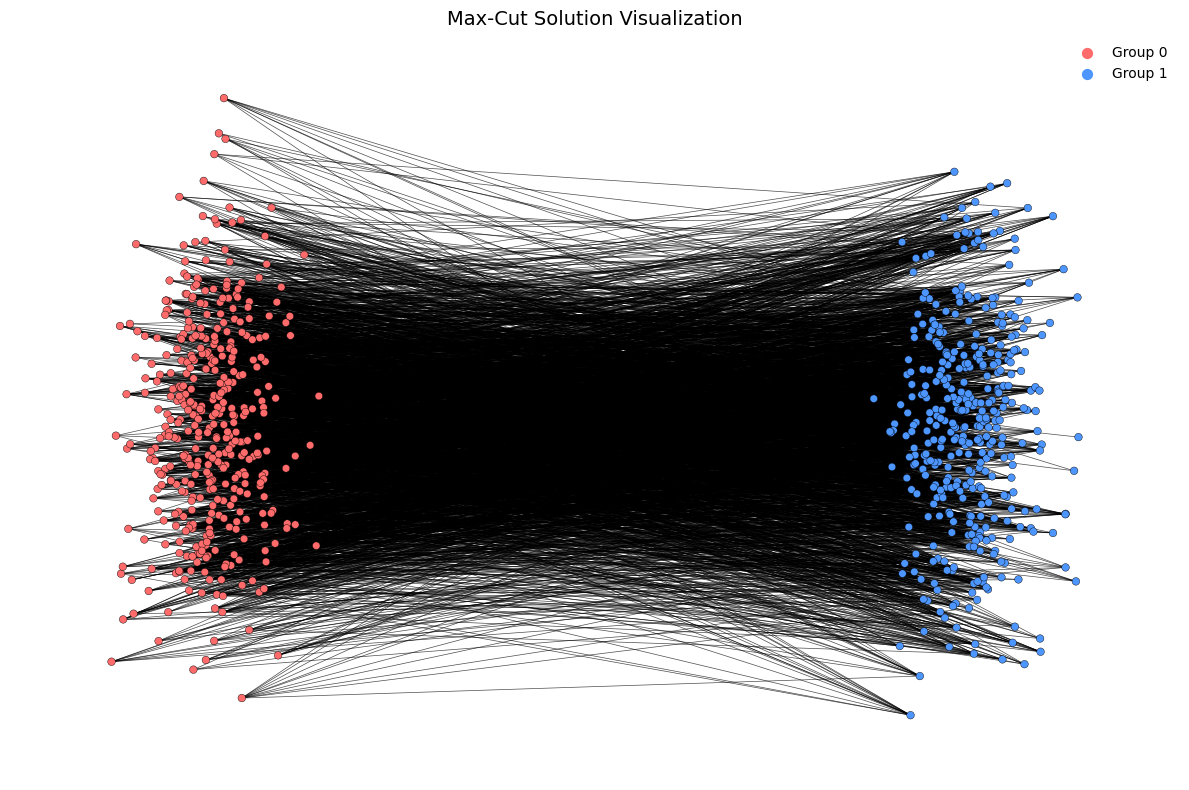

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Parameters
n_nodes = 800
edge_probability = 0.02  # Adjust for sparser/denser graphs
cluster_std = 0.1        # Controls cluster tightness

# Generate random graph
G = nx.gnp_random_graph(n_nodes, edge_probability, seed=42)

# Random partition (replace with your actual solution)
partition = {node: np.random.randint(0, 2) for node in G.nodes()}

# Create color mapping and edge lists
group0_color = '#FF6B6B'  # Red
group1_color = '#4D96FF'  # Blue
color_map = [group0_color if partition[node] == 0 else group1_color for node in G.nodes()]
cut_edges = [(u, v) for u, v in G.edges() if partition[u] != partition[v]]

# Generate clustered node positions
pos = {}
for node in G.nodes():
    if partition[node] == 0:
        pos[node] = (np.random.normal(-1, cluster_std), 
                    np.random.normal(0, cluster_std))
    else:
        pos[node] = (np.random.normal(1, cluster_std), 
                    np.random.normal(0, cluster_std))

# Create visualization
plt.figure(figsize=(12, 8))

# Draw cut edges
nx.draw_networkx_edges(G, pos, 
                       edgelist=cut_edges,
                       edge_color='black', 
                       width=0.5, 
                       alpha=0.7)

# Draw nodes
nx.draw_networkx_nodes(G, pos, 
                       node_color=color_map, 
                       node_size=30, 
                       edgecolors='black',
                       linewidths=0.3)

plt.title('Max-Cut Solution Visualization', fontsize=14)
plt.axis('off')

# Create legend
plt.scatter([], [], c=group0_color, label='Group 0', s=50)
plt.scatter([], [], c=group1_color, label='Group 1', s=50)
plt.legend(loc='best', frameon=False)

plt.tight_layout()
plt.show()

In [31]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
from matplotlib.colors import ListedColormap
from tqdm import tqdm

def create_maxcut_animation(Q, trajectory, output_file='animation.mp4', 
                           downsample=5, fps=15, dpi=200,
                           layout_iterations=50, node_size=15):
    """
    Create an animation of evolving Max-Cut solutions
    """
    # Create graph from connectivity matrix
    G = nx.from_numpy_array(Q)
    
    # Compute initial layout
    print("Computing graph layout...")
    pos = nx.spring_layout(G, iterations=layout_iterations, seed=42)
    
    # Set up figure and colormap
    fig = plt.figure(figsize=(10, 10), dpi=dpi)
    ax = fig.add_subplot(111)
    plt.axis('off')
    
    # Create custom colormap for our two groups
    cmap = ListedColormap(['#FF6B6B', '#4D96FF'])
    
    # Convert trajectory to integers and ensure binary values
    trajectory = np.where(trajectory < 0.5, 0, 1)  # Convert to 0/1
    
    # Draw static elements
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.1, edge_color='grey')
    nodes = nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size,
                                 node_color=trajectory[0], cmap=cmap,
                                 edgecolors='black', linewidths=0.3)
    
    # Set up video writer
    metadata = dict(title='Max-Cut Solution Trajectory', artist='Matplotlib')
    writer = FFMpegWriter(fps=fps, metadata=metadata)
    
    print("Rendering animation...")
    with writer.saving(fig, output_file, dpi=dpi):
        for i in tqdm(range(0, len(trajectory), downsample)):
            # Update node colors using numerical values
            nodes.set_array(trajectory[i])
            
            x = np.where(trajectory[i] < 0.5, 0, 1)
            cut_value = 0.5*(np.sum(Q * np.outer(x, 1 - x) + Q * np.outer(1 - x, x)))
            plt.title(f'Best Solution Found: {i}, quality = {cut_value}', fontsize=16)
            writer.grab_frame()
    
    plt.close(fig)

# Modified data loading
Q = np.load('G15.npy')

with open("s2.txt", "r") as f:
    trajectory = []
    for line in f:
        # Convert to numpy array and ensure numerical values
        trajectory.append(np.array([float(x) for x in line.split(",")]))
        
trajectory = np.array(trajectory)
trajectory = np.where(trajectory < 0.5, 0, 1)  # Force binary values

create_maxcut_animation(Q, trajectory, downsample=1, node_size=50)

Computing graph layout...
Rendering animation...


100%|██████████| 474/474 [01:08<00:00,  6.97it/s]


Computing graph layout...
Rendering animation...


  0%|          | 0/95 [00:00<?, ?it/s]


TypeError: Image data of dtype <U7 cannot be converted to float

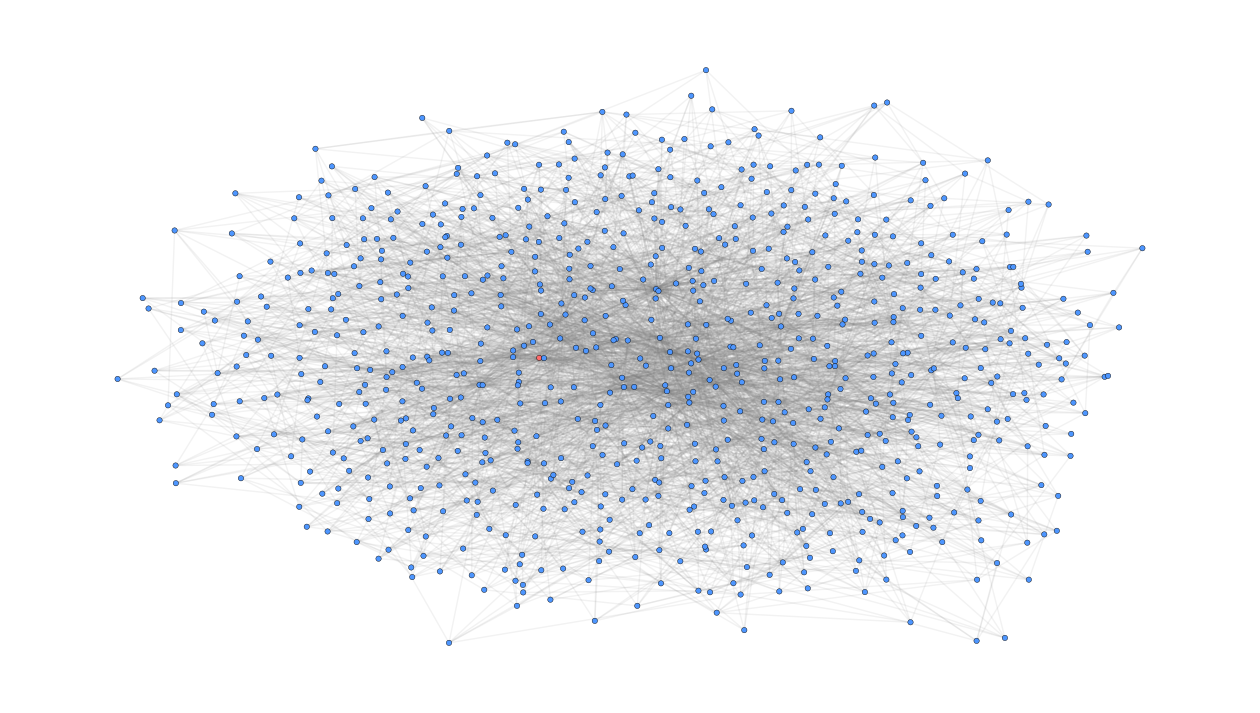